# Question:

In a standard game of Battleship, how many turns will pass before I can expect to hit my first ship?

I will be simulating selecting a random spot on the board and whether the shot hits a ship with the board state as follows
Occupied squares:

B2, B3, B4, B5, B6
F8, G8, H8, I8
D10, E10, F10
H3, H4, H5
J1, J2

one trial can produce the result of hitting a ship or hitting nothing

In [1]:
import pandas as pd
import seaborn as sns
import numpy as np
import random
import matplotlib.pyplot as plt
from math import comb

In [2]:
occupied_squares = {"B2","B3","B4","B5","B6","F8","G8","H8","I8","D10","E10","F10","H3","H4","H5","J1","J2"}

In [3]:
rows = "ABCDEFGHIJ"

In [4]:
cols = range(1,11)

In [5]:
all_squares = [f"{r}{c}" for r in rows for c in cols]

In [6]:
N = len(all_squares) # 100

In [7]:
K = len(occupied_squares) # 17

In [8]:
NUM_SIMULATIONS = 100000

In [9]:
first_hit_turns = []

In [10]:
for _ in range(NUM_SIMULATIONS):
    guesses = random.sample(all_squares, len(all_squares))
    for turn, guess in enumerate(guesses, start=1):
        if guess in occupied_squares:
            first_hit_turns.append(turn)
            break

In [11]:
sim_series = pd.Series(first_hit_turns)

In [12]:
sim_prob = (
sim_series
.value_counts(normalize=True)
.sort_index())

In [13]:
theoretical_probs = []

In [14]:
for t in range(1, N-K+2):
    prob = (comb(N-K, t-1) / comb(N, t-1)) * (K / (N-(t-1)))
    theoretical_probs.append(prob)
    theoretical_df = pd.DataFrame({"Turn": range(1, len(theoretical_probs)+1),"Theoretical Probability": theoretical_probs})

In [15]:
sim_df = pd.DataFrame({"Turn": sim_prob.index,"Simulated Probability": sim_prob.values})

In [16]:
plot_df = pd.merge(theoretical_df,sim_df,on="Turn",how="left").fillna(0)

In [17]:
expected_turn = np.mean(first_hit_turns)

In [18]:
theoretical_mean = (N + 1) / (K + 1)

In [19]:
print(f"Simulated Mean Turn: {expected_turn:.4f}")

Simulated Mean Turn: 5.6124


In [20]:
print(f"Theoretical Mean Turn: {theoretical_mean:.4f}")

Theoretical Mean Turn: 5.6111


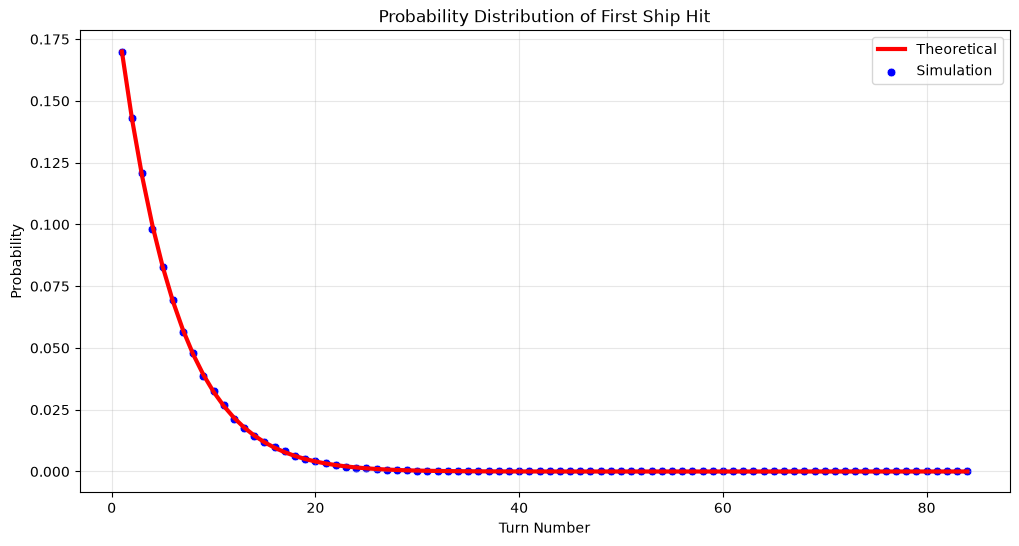

In [21]:
plt.figure(figsize=(12,6))
sns.lineplot(data=plot_df,x="Turn",y="Theoretical Probability",color="red",linewidth=3,label="Theoretical")
sns.scatterplot(data=plot_df,x="Turn",y="Simulated Probability",color="blue",s=40,label="Simulation")
plt.title("Probability Distribution of First Ship Hit")
plt.xlabel("Turn Number")
plt.ylabel("Probability")
plt.grid(True, alpha=.3)
plt.legend()
plt.show()

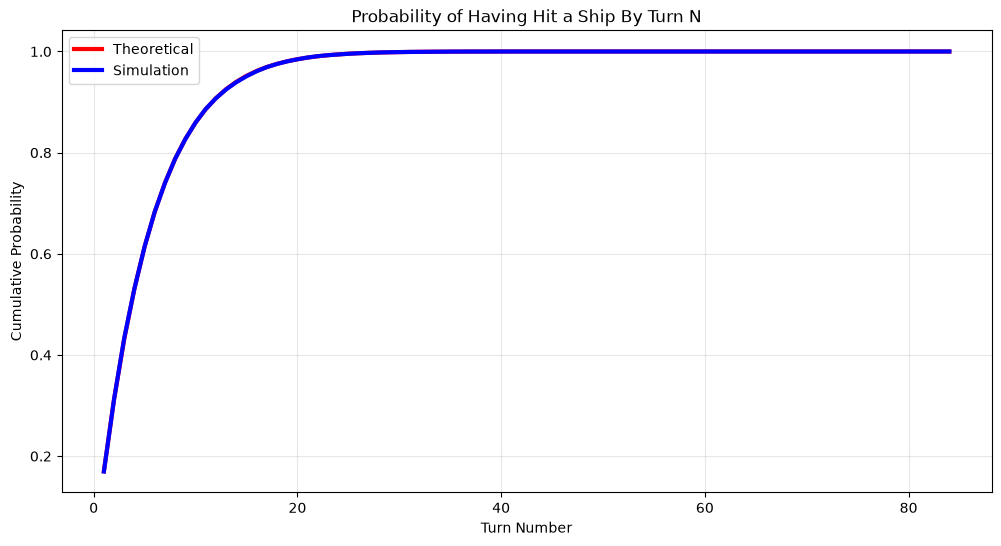

In [22]:
plot_df["Theoretical Cumulative"] = (plot_df["Theoretical Probability"].cumsum())
plot_df["Simulated Cumulative"] = (plot_df["Simulated Probability"].cumsum())
plt.figure(figsize=(12,6))
sns.lineplot(data=plot_df,x="Turn",y="Theoretical Cumulative",color="red",linewidth=3,label="Theoretical")
sns.lineplot(data=plot_df,x="Turn",y="Simulated Cumulative",color="blue",linewidth=3,label="Simulation")
plt.title("Probability of Having Hit a Ship By Turn N")
plt.xlabel("Turn Number")
plt.ylabel("Cumulative Probability")
plt.grid(True, alpha=.3)
plt.legend()
plt.show()

## My Conclusion:

in a game of Battleships, a player can, on average, expect to hit their first ship around turn five or six

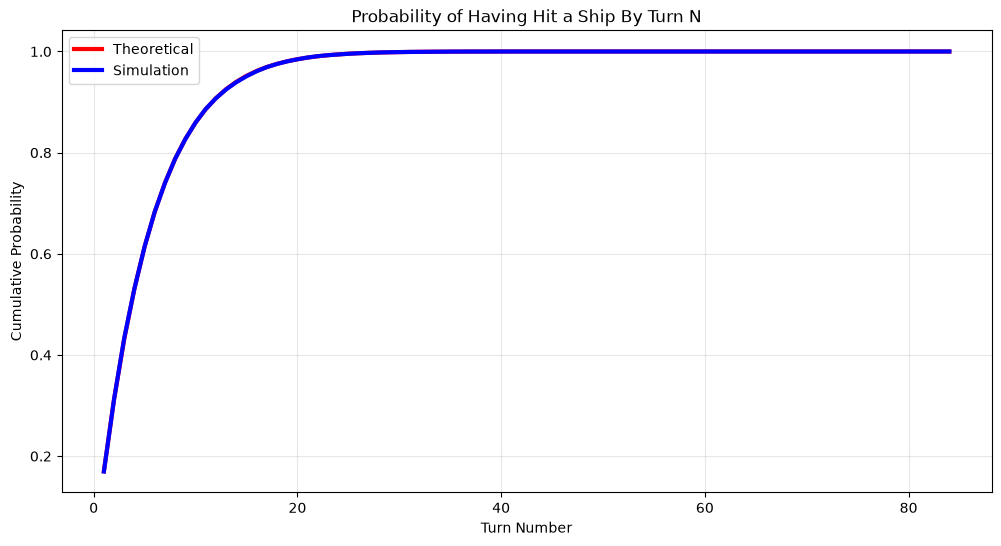

The graph shows the cumulative probability of hitting a ship in a standard game of Battleship, showing that around turn 7 you have a roughly 75 percent chance of hitting a ship, as well as that the simulated results almost perfectly match our theoretical cumulative probability